# 03 - Survival analysis: *when* do customers leave?

A churn classifier collapses time. Survival analysis keeps it: each customer
contributes time under observation, churners contribute an event, and customers
still subscribed at the snapshot are **right-censored** - they have not churned
*yet*, which is information, not a zero.

`tenure` is used here as time-to-event. That is the correct use of a column the
classifier deliberately excludes, because for churners it is how long they lasted.

Implemented with `lifelines`: Kaplan-Meier with confidence bands, log-rank tests,
restricted mean survival time (RMST), and a Cox model with a proportional-hazards
check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test

from telco_churn.data import load_clean

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = load_clean()
df = df[df.tenure > 0].copy()   # tenure 0 has no observed time at risk
print(f"{len(df):,} customers; {int(df.Churn.sum()):,} churn events; "
      f"{int((1 - df.Churn).sum()):,} right-censored at the snapshot")
print(f"Median observed tenure: {df.tenure.median():.0f} months")

7,032 customers; 1,869 churn events; 5,163 right-censored at the snapshot
Median observed tenure: 29 months


## 1. Kaplan-Meier curves by contract type

The curve is the estimated share still subscribed at each month. Shaded bands are
95% confidence intervals; they widen in the tail where few customers remain.

Month-to-month  survival at 12 months: 70.3%
One year        survival at 12 months: 99.1%
Two year        survival at 12 months: 100.0%


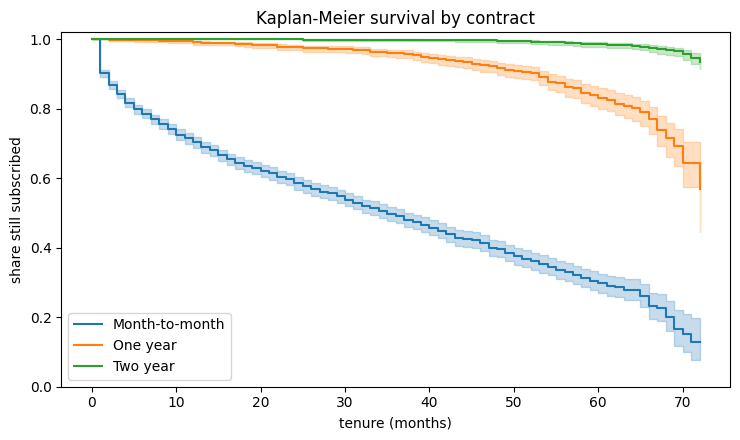

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
km = {}
for contract, g in df.groupby("Contract"):
    kmf = KaplanMeierFitter(label=contract).fit(g.tenure, g.Churn)
    km[contract] = kmf
    kmf.plot_survival_function(ax=ax, ci_show=True)
    s12 = float(kmf.survival_function_at_times(12).iloc[0])
    print(f"{contract:15s} survival at 12 months: {s12:.1%}")

ax.set_xlabel("tenure (months)")
ax.set_ylabel("share still subscribed")
ax.set_ylim(0, 1.02)
ax.set_title("Kaplan-Meier survival by contract")
plt.tight_layout()
plt.savefig(FIG / "03_kaplan_meier.png", dpi=140)
plt.show()

In [3]:
# Pairwise log-rank tests. With three groups these are unadjusted pairwise
# comparisons, so read them as description rather than three independent proofs.
rows = []
for a, b in combinations(sorted(km), 2):
    ga, gb = df[df.Contract == a], df[df.Contract == b]
    res = logrank_test(ga.tenure, gb.tenure, ga.Churn, gb.Churn)
    rows.append({"group A": a, "group B": b, "log-rank p": res.p_value})
logrank = pd.DataFrame(rows)
print(logrank.to_string(index=False, float_format=lambda x: f"{x:.2e}"))

       group A  group B  log-rank p
Month-to-month One year   2.12e-203
Month-to-month Two year    0.00e+00
      One year Two year    1.15e-57


## 2. How many months are lost? Restricted mean survival time

Hazard ratios are hard to brief. RMST answers a plainer question: in the first
24 months, how many months of subscription does an average customer in this group
actually deliver? The difference between groups is the time lost.

In [4]:
def rmst_at(kmf, tau: float) -> float:
    # Area under the Kaplan-Meier curve up to tau (months).
    sf = kmf.survival_function_
    t = np.r_[0.0, sf.index.to_numpy(dtype=float)]
    s = np.r_[1.0, sf.iloc[:, 0].to_numpy(dtype=float)]
    area = 0.0
    for i in range(len(t) - 1):
        if t[i] >= tau:
            break
        area += s[i] * (min(t[i + 1], tau) - t[i])
    return float(area)

rows = []
for contract, kmf in km.items():
    rows.append({"contract": contract, "RMST to 24 months": rmst_at(kmf, 24)})
rmst = pd.DataFrame(rows).set_index("contract")
rmst["months lost vs two-year"] = rmst["RMST to 24 months"].max() - rmst["RMST to 24 months"]
rmst.round(2)

,RMST to 24 months,months lost vs two-year
contract,,
Month-to-month,17.46,6.54
One year,23.80,0.20
Two year,24.00,0.00


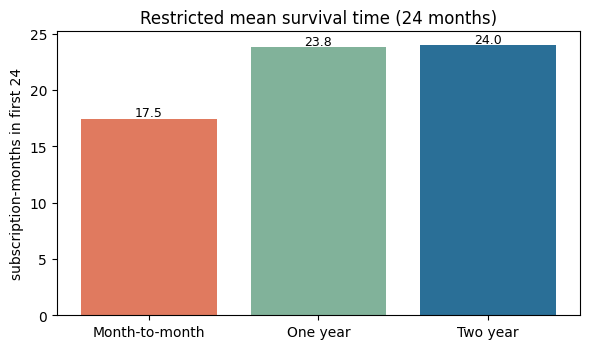

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(rmst.index, rmst["RMST to 24 months"], color=["#e07a5f", "#81b29a", "#2a6f97"])
ax.set_ylabel("subscription-months in first 24")
ax.set_title("Restricted mean survival time (24 months)")
for i, v in enumerate(rmst["RMST to 24 months"]):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "03_rmst.png", dpi=140)
plt.show()

## 3. Cox proportional hazards

A hazard ratio above 1 means leaving sooner per unit of the covariate, holding the
others fixed. Price enters as pounds per £10 of monthly charge.

In [6]:
df["price_per_10"] = df.MonthlyCharges / 10
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]
cox_df = pd.get_dummies(
    df[["tenure", "Churn", "price_per_10"] + cat_cols],
    columns=cat_cols, drop_first=True, dtype=float,
)
# Readable labels for the plot; the model is unchanged.
LABELS = {
    "price_per_10": "Price (+£10/month)",
    "Contract_One year": "Contract: one year",
    "Contract_Two year": "Contract: two year",
    "InternetService_Fiber optic": "Internet: fibre (vs DSL)",
    "InternetService_No": "Internet: none (vs DSL)",
    "PaymentMethod_Credit card (automatic)": "Payment: credit card",
    "PaymentMethod_Electronic check": "Payment: electronic check",
    "PaymentMethod_Mailed check": "Payment: mailed check",
    "PaperlessBilling_Yes": "Paperless billing",
}
cox_df = cox_df.rename(columns=LABELS)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="tenure", event_col="Churn")
print(f"Concordance index: {cph.concordance_index_:.3f} "
      f"({len(cox_df):,} rows, {int(cox_df.Churn.sum()):,} events)")
cph.summary[["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)

Concordance index: 0.843 (7,032 rows, 1,869 events)


,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
Price (+£10/month),-0.326,0.722,0.692,0.753,0.000
Contract: one year,-1.753,0.173,0.146,0.205,0.000
Contract: two year,-3.478,0.031,0.022,0.042,0.000
Internet: fibre (vs DSL),1.511,4.530,3.716,5.522,0.000
Internet: none (vs DSL),-1.306,0.271,0.213,0.345,0.000
Payment: credit card,-0.033,0.967,0.810,1.155,0.714
Payment: electronic check,0.687,1.989,1.732,2.284,0.000
Payment: mailed check,0.705,2.024,1.704,2.404,0.000
Paperless billing,0.184,1.202,1.076,1.342,0.001


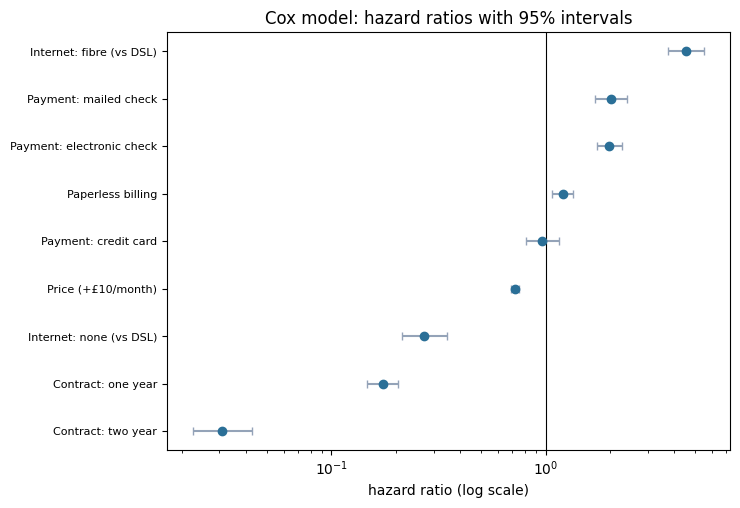

In [7]:
s = cph.summary.sort_values("exp(coef)")
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(s) + 1.4))
y = np.arange(len(s))
ax.errorbar(
    s["exp(coef)"], y,
    xerr=[s["exp(coef)"] - s["exp(coef) lower 95%"],
          s["exp(coef) upper 95%"] - s["exp(coef)"]],
    fmt="o", color="#2a6f97", ecolor="#94a3b8", capsize=3,
)
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(s.index, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("hazard ratio (log scale)")
ax.set_title("Cox model: hazard ratios with 95% intervals")
plt.tight_layout()
plt.savefig(FIG / "03_hr_forest.png", dpi=140)
plt.show()

## 4. Is the proportional-hazards assumption true?

The Cox model assumes each covariate's hazard ratio is constant over time. If
that fails, the ratio is an average over a changing effect and the reported
interval is too narrow. The test below correlates scaled Schoenfeld residuals
with time; small p-values are evidence against the assumption.

In [8]:
pht = proportional_hazard_test(cph, cox_df, time_transform="rank")
ph = pht.summary.sort_values("p")
print(ph.round(3).to_string())
print("\nViolations at p < 0.05:", list(ph.index[ph.p < 0.05]))

                           test_statistic      p  -log2(p)
Price (+£10/month)                 69.552  0.000    53.577
Contract: one year                 57.176  0.000    44.512
Contract: two year                 21.546  0.000    18.143
Internet: fibre (vs DSL)           19.863  0.000    16.875
Payment: mailed check              12.334  0.000    11.134
Payment: electronic check           6.237  0.013     6.321
Internet: none (vs DSL)             0.882  0.348     1.524
Payment: credit card                0.471  0.493     1.022
Paperless billing                   0.155  0.694     0.528

Violations at p < 0.05: ['Price (+£10/month)', 'Contract: one year', 'Contract: two year', 'Internet: fibre (vs DSL)', 'Payment: mailed check', 'Payment: electronic check']


Several covariates fail, contract most spectacularly. That is expected: the
protection of a long contract weakens as renewal approaches, so its hazard ratio
is not one number. The standard fix is to stratify the baseline hazard by
contract and estimate the other hazards within each contract group. That is not a
different question, just a weaker assumption.

In [9]:
# Stratify by contract: drop the contract dummies and let each contract group
# have its own baseline hazard.
strat_df = cox_df.drop(columns=["Contract: one year", "Contract: two year"]).copy()
strat_df["contract_stratum"] = pd.Categorical(df.Contract).codes

strat = CoxPHFitter()
strat.fit(strat_df, duration_col="tenure", event_col="Churn", strata=["contract_stratum"])
print(f"Stratified by contract - concordance {strat.concordance_index_:.3f}")
cols = ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
strat.summary.loc[[i for i in strat.summary.index if "Internet" in i or "Price" in i], cols].round(3)

Stratified by contract - concordance 0.666


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
Price (+£10/month),0.729,0.700,0.760,0.0
Internet: fibre (vs DSL),4.353,3.573,5.304,0.0
Internet: none (vs DSL),0.290,0.228,0.370,0.0


## Reading the result

- Contract length dominates. The 12-month survival gap between month-to-month and
  two-year customers is large, and the log-rank tests confirm it is not noise.
- Fibre customers leave sooner than DSL customers even after contract, payment
  method and price are held fixed. That is a stable association and a sensible
  place to look for a product or service-quality explanation.
- **Do not read the price hazard ratio as "higher prices keep customers".** It is
  the leftover association after service type and contract are controlled, and
  price is bundled with both. Notebook 04 takes this apart.
- The stratified model is the honest robustness check: if the fibre result
  survives it, the conclusion is not an artefact of the contract baseline.

## Limitations

- Observational data: hazard ratios are associations, not effects of changing
  price or contract.
- The snapshot censors everyone still subscribed at one point in time. That is
  handled, but it means the tail of the curve is thin and the wide bands there
  should not be read as precision.
- One event per customer. A real subscription business also has re-activations,
  dormancy and multiple spells, which need a different model.